In [14]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from scipy.stats import binomtest

In [2]:
def c2st(P, Q, test_size=0.5, seed=42, alpha=0.05):

    # Combine samples
    X = np.concatenate([P, Q]).reshape(-1, 1)

    # Origin labels
    y = np.concatenate([
        np.zeros(len(P), dtype=int),
        np.ones(len(Q), dtype=int)
    ])

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=seed,
        stratify=y
    )

    # Binary classifier
    classifier = LogisticRegression(
        random_state=seed
    )

    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)

    correct = np.sum(predictions == y_test)
    n_test = len(y_test)

    accuracy = correct / n_test

    # Exact test under H0: accuracy = 0.5
    p_value = binomtest(
        correct,
        n=n_test,
        p=0.5,
        alternative="greater"
    ).pvalue

    return {
        "accuracy": accuracy,
        "p_value": p_value,
        "reject_H0": p_value < alpha,
        "correct": correct,
        "n_test": n_test,
        "seed": seed
    }

In [3]:
# toy data generation
rng = np.random.default_rng(42)

n = 1000

P = rng.normal(loc=0, scale=1, size=n)
Q = rng.normal(loc=0, scale=1, size=n)

In [5]:
result = c2st(P, Q)
print(result)

{'accuracy': np.float64(0.52), 'p_value': np.float64(0.10872414660207075), 'reject_H0': np.False_, 'correct': np.int64(520), 'n_test': 1000, 'seed': 42}


#### 100 repettitions of the experiment

In [6]:
def repeat_c2st(mu_P, mu_Q, n=1000, repetitions=100):

    results = []

    for seed in range(repetitions):

        rng = np.random.default_rng(seed)

        P = rng.normal(
            loc=mu_P,
            scale=1,
            size=n
        )

        Q = rng.normal(
            loc=mu_Q,
            scale=1,
            size=n
        )

        result = c2st(
            P,
            Q,
            seed=seed
        )

        result["mu_P"] = mu_P
        result["mu_Q"] = mu_Q
        result["n"] = n

        results.append(result)

    return results

#### Known-answer test

- Same results: $P=N(0,1)$ , $Q=N(0,1)$
- Different results: $P=N(0,1)$ , $Q=N(3,1)$

In [8]:
same_results = repeat_c2st(
    mu_P=0,
    mu_Q=0,
    repetitions=100
)
same_results

[{'accuracy': np.float64(0.506),
  'p_value': np.float64(0.3639857989216804),
  'reject_H0': np.False_,
  'correct': np.int64(506),
  'n_test': 1000,
  'seed': 0,
  'mu_P': 0,
  'mu_Q': 0,
  'n': 1000},
 {'accuracy': np.float64(0.507),
  'p_value': np.float64(0.340511491638245),
  'reject_H0': np.False_,
  'correct': np.int64(507),
  'n_test': 1000,
  'seed': 1,
  'mu_P': 0,
  'mu_Q': 0,
  'n': 1000},
 {'accuracy': np.float64(0.498),
  'p_value': np.float64(0.5628114005424074),
  'reject_H0': np.False_,
  'correct': np.int64(498),
  'n_test': 1000,
  'seed': 2,
  'mu_P': 0,
  'mu_Q': 0,
  'n': 1000},
 {'accuracy': np.float64(0.499),
  'p_value': np.float64(0.5377871779298606),
  'reject_H0': np.False_,
  'correct': np.int64(499),
  'n_test': 1000,
  'seed': 3,
  'mu_P': 0,
  'mu_Q': 0,
  'n': 1000},
 {'accuracy': np.float64(0.48),
  'p_value': np.float64(0.902616835769117),
  'reject_H0': np.False_,
  'correct': np.int64(480),
  'n_test': 1000,
  'seed': 4,
  'mu_P': 0,
  'mu_Q': 0,
  

In [11]:
different_results = repeat_c2st(
    mu_P=0,
    mu_Q=3,
    repetitions=100
)
different_results

[{'accuracy': np.float64(0.94),
  'p_value': np.float64(1.967841384086047e-204),
  'reject_H0': np.True_,
  'correct': np.int64(940),
  'n_test': 1000,
  'seed': 0,
  'mu_P': 0,
  'mu_Q': 3,
  'n': 1000},
 {'accuracy': np.float64(0.94),
  'p_value': np.float64(1.967841384086047e-204),
  'reject_H0': np.True_,
  'correct': np.int64(940),
  'n_test': 1000,
  'seed': 1,
  'mu_P': 0,
  'mu_Q': 3,
  'n': 1000},
 {'accuracy': np.float64(0.93),
  'p_value': np.float64(7.103981575029298e-193),
  'reject_H0': np.True_,
  'correct': np.int64(930),
  'n_test': 1000,
  'seed': 2,
  'mu_P': 0,
  'mu_Q': 3,
  'n': 1000},
 {'accuracy': np.float64(0.923),
  'p_value': np.float64(3.478384136678237e-185),
  'reject_H0': np.True_,
  'correct': np.int64(923),
  'n_test': 1000,
  'seed': 3,
  'mu_P': 0,
  'mu_Q': 3,
  'n': 1000},
 {'accuracy': np.float64(0.943),
  'p_value': np.float64(4.816217868283219e-208),
  'reject_H0': np.True_,
  'correct': np.int64(943),
  'n_test': 1000,
  'seed': 4,
  'mu_P': 0,


#### Type-I error

$\text{Type I error} = P(\text{reject } H_0 \mid H_0 \text{ is true})$


`same_results` experiment, where $H_0$ is true: $ P = Q = N(0,1)$. Ratio of the times $H_0$ was rejected when it was true. 
Type-I error: $$\dfrac{\text{number of times } H_0 \text{ was rejected}}{\text{number of experiments}}$$ Since $\alpha = 0.5$, $\alpha > $ Type-I error.


In [13]:
n_rejections = sum(
    result["reject_H0"]
    for result in same_results
)

n_experiments = len(same_results)

type1_error = n_rejections / n_experiments

print("Experiments:", n_experiments)
print("Incorrect H0 rejections:", n_rejections)
print("Estimated Type I error:", type1_error)

Experiments: 100
Incorrect H0 rejections: 0
Estimated Type I error: 0.0


Type-I error is 0. $H_0$ was never incorrectly rejected, there were no false positives. The Type-1 error is lower than $\alpha = 0.5$, which is expected behavior. 

In [15]:
## save to .csv
same_df = pd.DataFrame(same_results)
same_df["case"] = "same"

different_df = pd.DataFrame(different_results)
different_df["case"] = "different"

results_df = pd.concat(
    [same_df, different_df],
    ignore_index=True
)

results_df.to_csv(
    "../results/c2st_known_answer.csv",
    index=False
)

#### Power of the test  

$\text{Power} = P(\text{reject } H_0 \mid H_1 \text{ is true})$


Calculate power using `different_results`



In [16]:
power = np.mean([
    result["reject_H0"]
    for result in different_results
])

print("Estimated power:", power)

Estimated power: 1.0


In 100 repetitions, C2ST produced no Type I errors under $H_0$ and detected the difference in all 100 repetitions under $H_1$.
	

#### 1000 repetitions

In [18]:
same_results = repeat_c2st(
    mu_P=0,
    mu_Q=0,
    repetitions=1000
)

different_results = repeat_c2st(
    mu_P=0,
    mu_Q=3,
    repetitions=1000
)

In [19]:
n_rejections = sum(
    result["reject_H0"]
    for result in same_results
)

n_experiments = len(same_results)

type1_error = n_rejections / n_experiments

print("Experiments:", n_experiments)
print("Incorrect H0 rejections:", n_rejections)
print("Estimated Type I error:", type1_error)

Experiments: 1000
Incorrect H0 rejections: 28
Estimated Type I error: 0.028


In [20]:
power = np.mean([
    result["reject_H0"]
    for result in different_results
])

print("Estimated power:", power)

Estimated power: 1.0


In 1000 repetitions, there were 28 false positives and 0 false negatives. 

#### Harder test - smaller effects:

* Different results: 
- $P=N(0,1)$ vs $Q=N(0.3,1)$ 
- $P=N(0,1)$ vs $Q=N(0.1,1)$ 
- $P=N(0,1)$ vs $Q=N(0.3,1)$
- $P=N(0,1)$ vs $Q=N(0.5,1)$
- $P=N(0,1)$ vs $Q=N(1,1)$ 

In [21]:
# Mean differences we want to test
mu_values = [0, 0.1, 0.3, 0.5, 1.0]

repetitions = 1000
n = 1000

summary = []
all_results = []

for mu_Q in mu_values:

    # Run C2ST 1000 times
    results = repeat_c2st(
        mu_P=0,
        mu_Q=mu_Q,
        n=n,
        repetitions=repetitions
    )

    # Proportion of experiments where H0 was rejected
    rejection_rate = np.mean([
        result["reject_H0"]
        for result in results
    ])

    # Store every individual experiment
    for result in results:
        result["case"] = f"N(0,1) vs N({mu_Q},1)"
        all_results.append(result)

    # Under mu_Q = 0, rejection rate = Type I error
    if mu_Q == 0:
        metric = "Type I error"
    else:
        metric = "Power"

    summary.append({
        "comparison": f"N(0,1) vs N({mu_Q},1)",
        "mean_difference": mu_Q,
        "rejection_rate": rejection_rate,
        "interpretation": metric
    })


In [22]:
# Convert summary to dataframe
summary_df = pd.DataFrame(summary)

print(summary_df)

           comparison  mean_difference  rejection_rate interpretation
0    N(0,1) vs N(0,1)              0.0           0.028   Type I error
1  N(0,1) vs N(0.1,1)              0.1           0.302          Power
2  N(0,1) vs N(0.3,1)              0.3           0.980          Power
3  N(0,1) vs N(0.5,1)              0.5           1.000          Power
4  N(0,1) vs N(1.0,1)              1.0           1.000          Power


`mean_difference` difference between the 2 means of P and Q


`rejection_rate` percentaje out of the 1000 reps that rejected $H_0$ -> frequency in which the c2st finds differences between the 2 samples.

In this test, it is known that $H_1$ is true (rejecting $H_0$ is the correct decision), so $\text{rejection rate} = \text{estimated power}$

**Logic:** 

$$
\begin{cases} 
P = Q & \Rightarrow \text{rejection rate} = \text{Type I error} \\ 
P \neq Q & \Rightarrow \text{rejection rate} = \text{Power} 
\end{cases}
$$


In [23]:
# Every individual C2ST run
all_results_df = pd.DataFrame(all_results)

all_results_df.to_csv(
    "../results/c2st_sensitivity_runs.csv",
    index=False
)

# Summary
summary_df.to_csv(
    "../results/c2st_sensitivity_summary.csv",
    index=False
)

Matplotlib is building the font cache; this may take a moment.


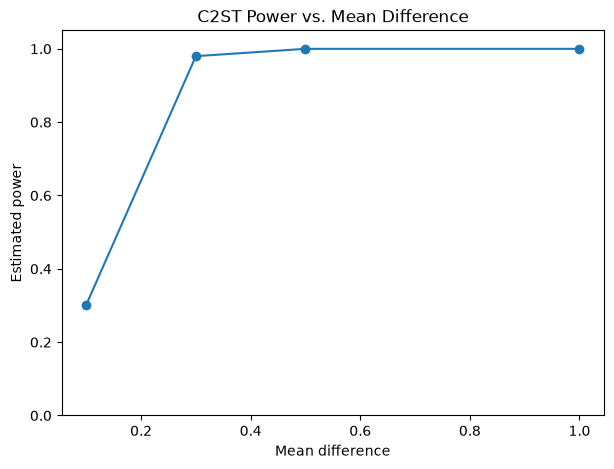

In [ ]:
# sensitivity curve
import matplotlib.pyplot as plt

power_df = summary_df[summary_df["mean_difference"] > 0]

plt.figure(figsize=(7, 5))

plt.plot(
    power_df["mean_difference"],
    power_df["rejection_rate"],
    marker="o"
)

plt.xlabel("Mean difference")
plt.ylabel("Estimated power")
plt.title("C2ST Power vs. Mean Difference")

plt.ylim(0, 1.05)

plt.show()

#### Interpretation of the C2ST sensitivity experiment

There is a clear trend: **larger differences between $P$ and $Q$ lead to higher statistical power**.

When the difference is small, with

$$
P = N(0,1), \qquad Q = N(0.1,1),
$$

the estimated power is only **0.302**. This means that C2ST detected the difference in approximately 3 out of every 10 repetitions. In the remaining 69.8% of repetitions, the test failed to reject $H_0$ even though the distributions were different, corresponding to a Type II error.

When the mean difference increases to

$$
P = N(0,1), \qquad Q = N(0.3,1),
$$

the estimated power increases to **0.980**, meaning that C2ST detected the difference in approximately 98 out of every 100 repetitions.

For mean differences of **0.5 and 1.0**, the estimated power was **1.0**. C2ST rejected $H_0$ in all 1000 repetitions. This does not mean that the true power of C2ST is exactly 100%; it means that the estimated power in these experiments was 1.0 based on the 1000 repetitions performed.

Under the null hypothesis,

$$
P = N(0,1), \qquad Q = N(0,1),
$$

the estimated Type I error was

$$
0.028 < \alpha = 0.05.
$$

Therefore, C2ST incorrectly rejected $H_0$ in 2.8% of the repetitions when the two distributions were actually identical. Overall, the experiment shows that the ability of C2ST to detect a difference increases as the separation between the two distributions becomes larger.